# 25 Modelldaten: Stundenwerte, Kennzahlen und Labels je Zähler

Teil 6: Lernende Modelle

**Worum es geht**
- Hier entsteht noch kein Modell. Das Notebook stellt die Daten bereit, aus denen die Notebooks 26 bis 29 lernen.
- Es legt fest, was ein Modell erkennen soll: ein Label (Zielmerkmal) je Fehlerart aus den Begehungen.
- Wichtigste Regel: Ein Modell, das Fehler vorhersagen soll, darf nur sehen, was vor der Begehung gemessen wurde. Danach ist der Fehler ja behoben.
- Stichtag ist der 1. September 2024. Davor lagen nur wenige Begehungen; bei diesen Zählern endet der Blick am Tag ihrer Begehung.

**Daten**
- liest: `data/processed/real_meters/<Zähler>.csv` und `hast_features.csv` (Anschlusswert) aus Notebook 00, Außentemperatur DWD Kitzingen, Begehungsprotokoll
- schreibt: `data/processed/modell_stunden.parquet`, `modell_kennzahlen.csv`, `modell_labels.csv`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/weather.py` (Wetter), `src/inspections.py` (Kästchen der Begehungen), `src/befundcodes.py` (Freitext-Befunde, siehe Notebook 14), `src/load_begehungen.py` (Zuordnung Begehung zu Zählernummer inkl. Zählerwechsel, siehe Notebook 02)
- Tests in `tests/test_befundcodes.py`

## 1 Wie es zu diesen Notebooks kam

- Die Notebooks 25 bis 30 sind nicht der erste Versuch, Fehler an den Hausstationen (HAST) zu finden.
- Jeder frühere Versuch hat etwas gezeigt, meistens, warum er allein nicht reicht.

| Versuch | wo | Ergebnis | was daraus folgte |
|---|---|---|---|
| Regeln mit festen Schwellen (5 Fehlerfamilien) | `src/fault_detection.py` | synthetische Daten 100 %, echte Daten viel zu breit | Schwellen lassen sich nicht übertragen, es braucht echte Labels |
| Klassifikator „Maßnahme ja/nein“ | `src/ml_classifier.py` | Label trifft auf 40 von 49 Stationen zu, schlägt die Baseline nicht | Label zu grob, hier deshalb ein Label je Fehlerart |
| K-Means auf Stationsmerkmalen | [`07`](../3_clustering/07_stationscluster.ipynb), [`10`](../3_clustering/10_tagescluster.ipynb) | keine natürlichen Gruppen (Silhouette unter 0,25) | K-Means nur mit klarem Zweck, siehe [`26`](26_einstufung.ipynb) |
| Kennlinienmonitor | [`13`](../4_stationsbilder/13_kennlinienmonitor.ipynb), [`14`](../4_stationsbilder/14_befunde.ipynb) | etwa 1,3-fach über Zufall; mechanische Eingriffe 10 von 19 | das Messsignal lohnt sich, wenn man weiß, wonach man sucht |
| Normalverhaltensmodell | [`18`](../5_monitoring/18_normalverhalten.ipynb) | Alarme treffen Begehungen zu 70 % gegen 53 % ohne Begehung | guter Wächter für den Winter, Vergleich in [`30`](30_waechtervergleich.ipynb) |
| Regeln und Kennzahlen je Fehlerart | lokale Vorarbeit | Ventil mit Sommernacht-Regel AUC 0,91, Dämmung mit keiner Regel über 0,5 | Regeln finden nur Bekanntes und nur im Sommer, siehe [`27`](27_lstm.ipynb) |

- AUC = Fläche unter der ROC-Kurve; 0,5 ist Zufall, 1 ist perfekt.
- Lehre: Ohne ein Label je Fehlerart lernt kein Modell etwas Brauchbares. Mit nur 53 begangenen Stationen lernt ein großes Modell die Fälle auswendig.
- Ausweg in den Notebooks 27 und 28: Ein LSTM (neuronales Netz für Zeitreihen) lernt zuerst ohne Labels, wie sich die Stationen verhalten. Erst danach kommen die Labels dazu.

| Notebook | Frage |
|---|---|
| 25 (dieses) | Welche Daten und welche Labels? |
| [`26`](26_einstufung.ipynb) | Läuft eine Station im Optimum oder schlechter? |
| [`27`](27_lstm.ipynb) | Welche Station hat welchen Fehler? (LSTM) |
| [`28`](28_prognose_lstm.ipynb) | Wo ändert sich gerade etwas? (Prognose-LSTM) |
| [`29`](29_xgboost.ipynb) | Bringen XGBoost und Co. mehr? Klassen der Folie 5 für jede Station |
| [`30`](30_waechtervergleich.ipynb) | Wie schlägt sich der LSTM-Wächter gegen das Normalverhaltensmodell? |

## 2 Setup

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*Data Validation extension.*")

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import befundcodes, inspections, load_begehungen
from src.load_data import load_inspections
from src.weather import load_outdoor_temperature

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

PROCESSED = ROOT / "data" / "processed"
METER_DIR = PROCESSED / "real_meters"

STICHTAG = pd.Timestamp("2024-09-01")
WINTER = (pd.Timestamp("2023-10-01"), pd.Timestamp("2024-04-01"))   #Heizperiode vor den Begehungen
SOMMER = (pd.Timestamp("2024-06-01"), pd.Timestamp("2024-09-01"))   #Sommer vor den Begehungen
print(f"{len(list(METER_DIR.glob('*.csv')))} Zählerreihen aus Notebook 00")

93 Zählerreihen aus Notebook 00


- Sucht die Projektwurzel und macht `src/` importierbar.
- Legt drei Zeiträume fest, die in allen Modell-Notebooks gleich sind: den Stichtag, den Winter 2023/24 und den Sommer 2024. Winter und Sommer liegen vor den Begehungen.

## 3 Die Stundenreihen aus Notebook 00

- Notebook 00 hat je Zähler eine Datei geschrieben: Exporte zusammengeführt, auf volle Stunden gerundet, unmögliche Werte entfernt, lückenloses Stundenraster.
- Hier werden alle 93 Dateien zu einer Tabelle zusammengelegt: eine Zeile je Zähler und Stunde.

In [2]:
SPALTEN = {
    "Timestamp": "timestamp",
    "Flow temperature (°C)": "vorlauf",
    "Return temperature (°C)": "ruecklauf",
    "Temperature difference (°C)": "spreizung",
    "Volume flow (l/h)": "durchfluss",
    "Power (kW)": "leistung",
}
teile = []
for pfad in sorted(METER_DIR.glob("*.csv")):
    df = pd.read_csv(pfad, usecols=list(SPALTEN), parse_dates=["Timestamp"]).rename(columns=SPALTEN)
    df.insert(0, "zaehler", int(pfad.stem))
    teile.append(df)
stunden = pd.concat(teile, ignore_index=True)

print(f"{len(stunden):,} Stundenzeilen von {stunden['zaehler'].nunique()} Zählern")
print(f"Zeitraum: {stunden['timestamp'].min():%d.%m.%Y} bis {stunden['timestamp'].max():%d.%m.%Y}")
print(f"davon mit Messwert: {stunden['ruecklauf'].notna().mean():.0%}")
stunden.head()

2,128,400 Stundenzeilen von 93 Zählern
Zeitraum: 01.11.2021 bis 20.07.2026
davon mit Messwert: 80%


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
0,53198226,2021-11-01 23:00:00,0.0,0.0,11.5,66.6,55.0
1,53198226,2021-11-02 00:00:00,NaN,NaN,NaN,NaN,NaN
2,53198226,2021-11-02 01:00:00,NaN,NaN,NaN,NaN,NaN
3,53198226,2021-11-02 02:00:00,NaN,NaN,NaN,NaN,NaN
4,53198226,2021-11-02 03:00:00,NaN,NaN,NaN,NaN,NaN


- Liest jede Zählerdatei, behält die fünf Messgrößen und gibt ihnen kurze deutsche Namen.
- Die Zählernummer kommt aus dem Dateinamen und steht in der ersten Spalte.
- Die leeren Zeilen sind gewollt: Notebook 00 legt für jede Stunde eine Zeile an, auch für nicht gemessene. So gilt „eine Zeile = eine Stunde“.

### 3.1 Erst einmal anschauen

- Welche Spalten und Datentypen gibt es, wie viel fehlt?
- Liegen die Werte in einem physikalisch sinnvollen Bereich?

In [3]:
stunden.info()

<class 'pandas.DataFrame'>
RangeIndex: 2128400 entries, 0 to 2128399
Data columns (total 7 columns):
 #   Column      Dtype         
---  ------      -----         
 0   zaehler     int64         
 1   timestamp   datetime64[us]
 2   durchfluss  float64       
 3   leistung    float64       
 4   spreizung   float64       
 5   vorlauf     float64       
 6   ruecklauf   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 113.7 MB


In [4]:
uebersicht = stunden.drop(columns=["zaehler", "timestamp"]).describe().T
uebersicht["fehlend"] = stunden.drop(columns=["zaehler", "timestamp"]).isna().mean().round(3)
uebersicht.round(1)

,count,mean,std,min,25%,50%,75%,max,fehlend
durchfluss,1692110.0,327.7,1405.3,-999.0,0.0,53.0,186.0,26135.0,0.2
leistung,1690145.0,5.2,24.4,-180.3,0.0,0.7,3.5,747.7,0.2
spreizung,1678654.0,16.7,13.6,-35.4,4.6,14.7,27.9,60.7,0.2
vorlauf,1692166.0,63.0,15.5,9.5,56.3,69.4,73.9,91.5,0.2
ruecklauf,1692166.0,46.2,15.3,8.6,33.0,45.7,57.1,89.0,0.2


- Sieben Spalten: Zählernummer, Zeitstempel und fünf Messgrößen. Zusammen 2,1 Mio. Zeilen, rund 114 MB im Speicher.
- Rund ein Fünftel jeder Messgröße fehlt (Spalte `fehlend`: 0,2). Das sind die Lücken aus Notebook 00 (dort: 80 % der Stunden gemessen).
- Die typischen Werte sind plausibel:
  - Vorlauf in der mittleren Hälfte der Stunden zwischen 56 und 74 °C, Rücklauf zwischen 33 und 57 °C.
  - Durchfluss im Median 53 l/h; einzelne große Abnehmer kommen auf über 20.000 l/h und über 700 kW.
- Es gibt unmögliche Ausreißer nach unten: Durchfluss bis −999 l/h, Leistung bis −180 kW. Notebook 00 lässt Werte zwischen −1000 und 50.000 l/h stehen. Für die Kennzahlen ist das unkritisch, sie nutzen nur Stunden mit Durchfluss über 1 bzw. 5 l/h. Das LSTM sieht diese Werte, sie sind aber sehr selten (25-%-Quantil bei 0).
- Spreizung = Vorlauf minus Rücklauf. Sie kann negativ sein, wenn ohne Durchfluss das stehende Wasser auskühlt. Spreizungs-Kennzahlen nutzen deshalb nur Stunden, in denen Wasser fließt.

In [5]:
BEISPIEL = stunden.groupby("zaehler")["ruecklauf"].count().idxmax()
beispiel = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= "2024-01-15")].head(24)
print(f"Ein Wintertag des Zählers {BEISPIEL} (der mit den meisten Messstunden):")
beispiel

Ein Wintertag des Zählers 68956347 (der mit den meisten Messstunden):


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
318040,68956347,2024-01-15 00:00:00,162.0,5.949,31.8,73.2,41.4
318041,68956347,2024-01-15 01:00:00,131.0,5.700,37.7,74.2,36.5
318042,68956347,2024-01-15 02:00:00,153.0,5.500,31.2,74.8,43.6
318043,68956347,2024-01-15 03:00:00,166.0,6.831,35.6,75.4,39.7
318044,68956347,2024-01-15 04:00:00,138.0,5.636,35.4,75.4,40.0
318045,68956347,2024-01-15 05:00:00,180.0,6.621,31.9,74.1,42.2
318046,68956347,2024-01-15 06:00:00,216.0,8.239,32.9,74.1,41.1
318047,68956347,2024-01-15 07:00:00,454.0,10.810,20.7,74.5,53.7
318048,68956347,2024-01-15 08:00:00,476.0,6.712,12.3,76.0,63.7
318049,68956347,2024-01-15 09:00:00,462.0,4.822,9.1,73.8,64.6


- Der Vorlauf kommt vom Netz und schwankt wenig.
- Durchfluss und Leistung gehen mit dem Wärmebedarf hoch und runter.
- Die Spreizung zeigt, wie viel Wärme die Station dem Wasser entzieht.
- Leistung ≈ 1,16 · Durchfluss [m³/h] · Spreizung: Die drei Größen hängen physikalisch zusammen.

## 4 Außentemperatur dazu

- Wie viel eine Station heizt, hängt vor allem am Wetter. Ein Modell ohne Wetter hält jeden kalten Tag für auffällig.
- Die Außentemperatur kommt aus `src/weather.py` (DWD-Station Kitzingen, auf dieselbe Lokalzeit gebracht wie die Zählerexporte).

Wetter: 41,312 Stunden, Spalten ['timestamp', 't_out', 'interpolated']
count    41303.0
mean        11.2
std          8.5
min        -13.8
25%          4.7
50%         10.5
75%         17.1
max         40.4
davon linear aufgefüllt (Lücken bis 6 h): 7 Stunden

Außentemperatur fehlt nach dem Anhängen in 0.03% der Stunden


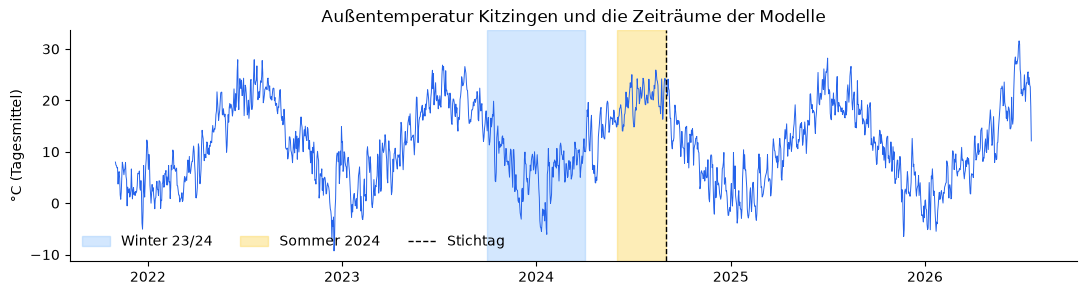

In [6]:
wetter = load_outdoor_temperature(stunden["timestamp"].min(), stunden["timestamp"].max())
print(f"Wetter: {wetter.shape[0]:,} Stunden, Spalten {list(wetter.columns)}")
print(wetter["t_out"].describe().round(1).to_string())
print(f"davon linear aufgefüllt (Lücken bis 6 h): {wetter['interpolated'].sum()} Stunden")
wetter = wetter.rename(columns={"t_out": "aussen"})[["timestamp", "aussen"]]
stunden = stunden.merge(wetter, on="timestamp", how="left")
print(f"\nAußentemperatur fehlt nach dem Anhängen in {stunden['aussen'].isna().mean():.2%} der Stunden")

tagesmittel = wetter.set_index("timestamp")["aussen"].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(tagesmittel.index, tagesmittel, lw=0.7, color="#2563EB")
for (von, bis), farbe, name in ((WINTER, "#93C5FD", "Winter 23/24"), (SOMMER, "#FCD34D", "Sommer 2024")):
    ax.axvspan(von, bis, color=farbe, alpha=0.4, label=name)
ax.axvline(STICHTAG, color="black", ls="--", lw=1, label="Stichtag")
ax.set_ylabel("°C (Tagesmittel)")
ax.set_title("Außentemperatur Kitzingen und die Zeiträume der Modelle")
ax.legend(frameon=False, ncol=3, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Holt die stündliche Außentemperatur (beim ersten Lauf von DWD Open Data, danach aus dem Cache in `data/raw/weather/`) und hängt sie per Zeitstempel an.
- Die Grafik zeigt die Zeiträume, die die Modelle später nutzen. Alles links der gestrichelten Linie liegt vor den Begehungen.

## 5 Wie viele brauchbare Tage hat jeder Zähler?

- Die LSTM-Modelle in Notebook 27 und 28 lesen ganze Tage, also 24 Stunden am Stück.
- Ein Tag zählt nur, wenn alle 24 Stunden aller Größen gemessen sind.
- Lücken werden nicht gefüllt: Das Netz würde sonst erfundene Stunden lernen.

In [7]:
KANAELE = ["vorlauf", "ruecklauf", "spreizung", "durchfluss", "leistung", "aussen"]
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden["vollstaendig"] = stunden[KANAELE].notna().all(axis=1)
tage = stunden.groupby(["zaehler", "tag"])["vollstaendig"].sum().rename("stunden").reset_index()
tage["voll"] = tage["stunden"] == 24

ZEITRAEUME = {
    "Winter 22/23": ("2022-10-01", "2023-04-01"),
    "Winter 23/24": ("2023-10-01", "2024-04-01"),
    "Sommer 2024": ("2024-06-01", "2024-09-01"),
    "ab Stichtag": ("2024-09-01", "2030-01-01"),
}
volle_tage = pd.DataFrame({
    name: tage[(tage["tag"] >= von) & (tage["tag"] < bis) & tage["voll"]].groupby("zaehler").size()
    for name, (von, bis) in ZEITRAEUME.items()
}).reindex(stunden["zaehler"].unique()).fillna(0).astype(int)
volle_tage.index.name = "zaehler"
print(f"Vollständige Tage insgesamt: {tage['voll'].sum():,} von {len(tage):,}")
volle_tage.describe().round(0)

Vollständige Tage insgesamt: 67,840 von 88,792


,Winter 22/23,Winter 23/24,Sommer 2024,ab Stichtag
count,93.0,93.0,93.0,93.0
mean,60.0,156.0,78.0,294.0
std,68.0,47.0,28.0,127.0
min,0.0,0.0,0.0,0.0
25%,0.0,143.0,89.0,298.0
50%,0.0,180.0,90.0,308.0
75%,137.0,180.0,90.0,309.0
max,138.0,181.0,90.0,680.0


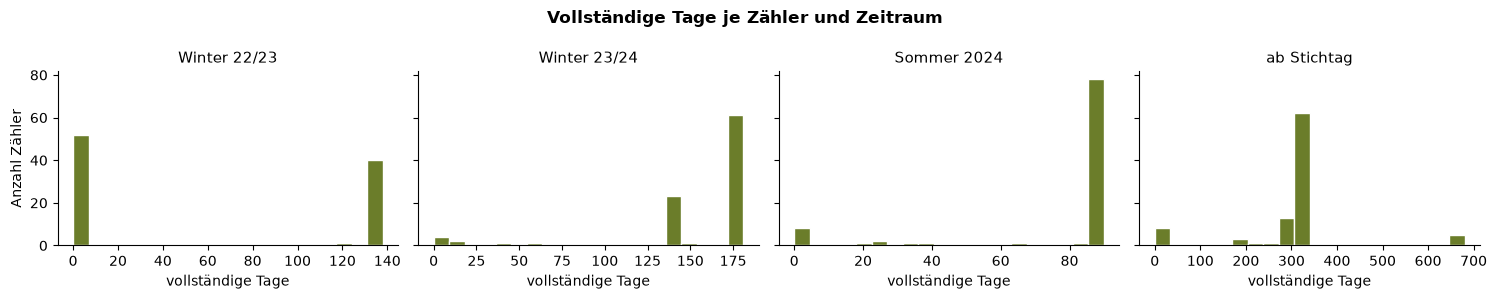

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, name in zip(axes, volle_tage.columns):
    ax.hist(volle_tage[name], bins=20, color="#6B7D2A", edgecolor="white")
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("vollständige Tage")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anzahl Zähler")
fig.suptitle("Vollständige Tage je Zähler und Zeitraum", fontweight="bold")
fig.tight_layout()
plt.show()

- Je Zähler und Tag wird gezählt, wie viele Stunden alle sechs Größen haben. Nur Tage mit 24 solchen Stunden sind „voll“.
- Die Tabelle zählt die vollen Tage je Zeitraum. Ein Winter hat 182 Tage, der Sommer 92.
- Der Tag der Zeitumstellung im März hat nur 23 Stunden und fällt deshalb immer heraus. Das kostet einen Tag im Jahr.

- Von knapp 89.000 Zähler-Tagen sind knapp 68.000 vollständig. Die übrigen haben Lücken, oft nur einzelne Stunden.
- Winter 23/24 und Sommer 2024 sind gut abgedeckt: im Median 180 von 182 Wintertagen und 90 von 92 Sommertagen. Auf diesen beiden Zeiträumen bauen die Modelle auf.
- Winter 22/23 hat nur knapp die Hälfte: 41 Zähler haben dort mindestens 60 volle Tage, der Rest kam erst 2023 dazu (zwei Rollout-Wellen, siehe Notebook 00). Vergleiche über zwei Winter (Notebook 27) gehen deshalb nur mit diesen 41 Zählern.
- Nach dem Stichtag hat ein typischer Zähler gut 300 volle Tage. Das reicht, um in Notebook 28 die Zeit nach den Begehungen zu beobachten.

## 6 Labels aus den Begehungen

- Was ein Modell erkennen soll, steht im Begehungsprotokoll (66 Begehungen).
- Quelle 1, Kästchen (`src/inspections.py`): Filter gereinigt, Durchfluss eingestellt, Leitungen gedämmt, Stellmotor bzw. Stellventil getauscht, Vertragsleistung alt/neu.
- Quelle 2, Freitext „Sonstiges“ (`src/befundcodes.py`): Viele Befunde stehen nur dort, etwa ein klemmendes Regelventil.
- Zuerst ein Blick darauf, wie die Kästchen ausgefüllt wurden. Das erklärt später, warum manche Fehlerarten nicht lernbar sind.

In [9]:
roh = load_inspections()
#Rohtabelle enthält Adressen, deshalb nur Größe und Spaltennamen
print(f"Begehungsprotokoll: {roh.shape[0]} Zeilen × {roh.shape[1]} Spalten")
print("Spalten (Auswahl):", [c.replace("\n", " ") for c in roh.columns[:12]], "...")

Begehungsprotokoll: 66 Zeilen × 134 Spalten
Spalten (Auswahl): ['Nr.', 'Datum', 'Straßenname', 'Hausnummer', 'Dauer (Uhrzeit)', 'Dauer (Uhrzeit)', 'Anlagen- konfiguration auf Seite 125', 'Station auf Seite 125', 'Zusatz- heizungen', 'Anzahl Personen', 'beheizte Wohnfläche', 'Inbetriebnahmejahr'] ...


- Lädt das Begehungsprotokoll (66 Begehungen, über 100 Spalten mit zweizeiligem Kopf).
- Gezeigt werden nur Größe und erste Spaltennamen. Die Zeilen enthalten Adressen und werden in keinem dieser Notebooks angezeigt.

In [10]:
KAESTCHEN = {
    "Filter gereinigt": "Filter\ngereinigt",
    "Durchfluss eingestellt": "Durchfluss neu\neingestellt",
    "Leitungen gedämmt": "Leitungen\nneu gedämmt",
    "Stellmotor getauscht": "Stellmotor\ngetauscht",
    "Stellventil getauscht": "Stellventil\ngetauscht",
}

def zustand(wert):
    w = str(wert).strip().lower()
    if w == "ja":
        return "ja"
    if w == "nein":
        return "ausdrücklich nein"
    return "leer"

ausfuellung = pd.DataFrame({name: roh[spalte].map(zustand).value_counts() for name, spalte in KAESTCHEN.items()}).T
ausfuellung = ausfuellung.reindex(columns=["ja", "ausdrücklich nein", "leer"]).fillna(0).astype(int)
ausfuellung

,ja,ausdrücklich nein,leer
Filter gereinigt,31,4,31
Durchfluss eingestellt,23,6,37
Leitungen gedämmt,23,8,35
Stellmotor getauscht,2,11,53
Stellventil getauscht,2,12,52


- Zählt je Kästchen, wie oft „ja“, wie oft ausdrücklich „nein“ und wie oft nichts eingetragen ist.

- Die Kästchen wurden fast nur ausgefüllt, wenn etwas gemacht wurde. Ein ausdrückliches „nein“ steht beim Filter 4-mal, beim Durchfluss 6-mal, bei der Dämmung 8-mal. In jeweils rund der Hälfte der Zeilen steht nichts.
- Für ein Modell heißt das: Die Gegenbeispiele („kein Filterproblem“) sind fast alle leere Kästchen. Ob dort wirklich nichts war, weiß niemand. Wer „leer“ als „nein“ liest, trifft eine Annahme.
- Stellmotor und Stellventil sind nur je 2-mal angekreuzt. Die meisten Ventilbefunde stehen im Freitext. Das Ventil-Label nimmt deshalb beide Quellen zusammen.

In [11]:
tidy = inspections.tidy_inspections()
zaehler_mit_reihe = set(stunden["zaehler"].unique())
kodiert = befundcodes.kodiere_begehungen(load_begehungen.begehungen_mit_zaehler(available=zaehler_mit_reihe))

#beide Loader müssen dieselben 66 Zeilen in gleicher Reihenfolge lesen
assert len(tidy) == len(kodiert) and (tidy["address_norm"].values == kodiert["key"].values).all()

soll_alt = pd.to_numeric(kodiert["rw_soll_tag_alt"], errors="coerce")
soll_neu = pd.to_numeric(kodiert["rw_soll_tag_neu"], errors="coerce")
vertrag_bekannt = tidy["vertrag_alt_kw"].notna() & tidy["vertrag_neu_kw"].notna()

begehungen = pd.DataFrame({
    "zaehler": kodiert["meter"].astype(int),
    "datum": pd.to_datetime(kodiert["datum"], errors="coerce"),
    "ventil": tidy["stellventil_getauscht"] | tidy["stellmotor_getauscht"] | kodiert["ventil_stellantrieb"],
    "daemmung": tidy["daemmung_neu"] | kodiert["daemmung"],
    "filter": tidy["filter_gereinigt"],
    "durchfluss": tidy["durchfluss_neu"],
    "temperatur": soll_neu < soll_alt,
    "ueberdimensioniert": (tidy["vertrag_neu_kw"] < tidy["vertrag_alt_kw"]).astype(float).where(vertrag_bekannt),
    #Vertragsleistung vor der Begehung (für die Auslastung)
    "vertrag_alt_kw": tidy["vertrag_alt_kw"],
    "vertrag_neu_kw": tidy["vertrag_neu_kw"],
    #Straße nur als Nummer, damit später ganze Straßen ausgelassen werden können
    "strasse_gruppe": pd.factorize(tidy["address_norm"].str.rsplit(" ", n=1).str[0])[0],
})
print(f"{len(begehungen)} Begehungen, {begehungen['zaehler'].nunique()} verschiedene Zähler, "
      f"davon mit Zeitreihe: {begehungen['zaehler'].isin(zaehler_mit_reihe).sum()} Begehungen")
begehungen.head()

66 Begehungen, 62 verschiedene Zähler, davon mit Zeitreihe: 59 Begehungen


,zaehler,datum,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert,vertrag_alt_kw,vertrag_neu_kw,strasse_gruppe
0,72167782,NaT,True,True,False,True,True,NaN,NaN,NaN,0
1,68956367,2025-09-12,False,False,True,False,True,0.0,8.0,8.0,0
2,68956348,2024-09-09,False,False,True,True,False,NaN,NaN,NaN,0
3,68956353,2024-09-23,False,True,False,True,True,0.0,8.0,8.0,1
4,80912195,2024-09-11,False,False,False,False,False,NaN,NaN,NaN,1


In [12]:
#kurzer Blick: Datentypen und fehlende Werte je Spalte
werte = begehungen.drop(columns=["zaehler", "strasse_gruppe"]).select_dtypes(["bool", "number"])
pd.DataFrame({"Typ": begehungen.dtypes.astype(str), "fehlend": begehungen.isna().sum(),
              "Anteil ja / Mittelwert": werte.mean().round(2)})

,Typ,fehlend,Anteil ja / Mittelwert
daemmung,bool,0,0.39
datum,datetime64[us],8,NaN
durchfluss,bool,0,0.35
filter,bool,0,0.47
strasse_gruppe,int64,0,NaN
temperatur,bool,0,0.56
ueberdimensioniert,float64,22,0.20
ventil,bool,0,0.17
vertrag_alt_kw,float64,22,10.36
vertrag_neu_kw,float64,19,10.19


- `tidy_inspections()` liefert die Kästchen, `kodiere_begehungen()` die Freitext-Befunde samt Zählernummer. Bei Zählerwechsel wird der Zähler gewählt, für den es eine Zeitreihe gibt.
- Je Begehung entstehen sechs Labels:

| Label | ja, wenn … |
|---|---|
| `ventil` | Stellventil oder Stellmotor getauscht oder Ventilbefund im Freitext |
| `daemmung` | Leitungen gedämmt oder Dämmungsbefund im Freitext |
| `filter` | Filter gereinigt |
| `durchfluss` | Durchfluss neu eingestellt |
| `temperatur` | Rücklauf-Sollwert tagsüber gesenkt |
| `ueberdimensioniert` | Vertragsleistung neu kleiner als alt (leer, wenn nicht beide eingetragen) |

- Lesart „leer ist nein“: Ein leeres Kästchen zählt als „nein“. Das ist eine Annahme; die Tabelle oben zeigt, wie viel daran hängt.
- Zweite Tabelle: Die Kästchen-Labels sind immer gefüllt (wegen „leer ist nein“). Bei 8 Begehungen fehlt das Datum, bei 22 die Vertragsleistung; dort ist „überdimensioniert“ leer.
- Die Adresse dient nur dem Abgleich und wird nicht weitergegeben. Übrig bleibt eine Nummer je Straße.

In [13]:
LABELS = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
labels = begehungen.groupby("zaehler").agg(
    begehungen=("datum", "size"),
    erste_begehung=("datum", "min"),
    strasse_gruppe=("strasse_gruppe", "first"),
    vertrag_alt_kw=("vertrag_alt_kw", "first"),
    vertrag_neu_kw=("vertrag_neu_kw", "first"),
    **{name: (name, "max") for name in LABELS},
)
labels = labels[labels.index.isin(zaehler_mit_reihe)]
for name in LABELS[:-1]:
    labels[name] = labels[name].astype(bool)

basisraten = pd.DataFrame({
    "Fälle": labels[LABELS].sum().astype(int),
    "bekannt": labels[LABELS].notna().sum(),
})
basisraten["Anteil"] = (basisraten["Fälle"] / basisraten["bekannt"]).round(2)
print(f"{len(labels)} begangene Zähler mit Zeitreihe; {(labels['begehungen'] > 1).sum()} davon mehrfach begangen")
print(f"Begehungen vor dem Stichtag: {(labels['erste_begehung'] < STICHTAG).sum()}")
basisraten

56 begangene Zähler mit Zeitreihe; 3 davon mehrfach begangen
Begehungen vor dem Stichtag: 2


,Fälle,bekannt,Anteil
ventil,11,56,0.20
daemmung,23,56,0.41
filter,26,56,0.46
durchfluss,20,56,0.36
temperatur,36,56,0.64
ueberdimensioniert,9,37,0.24


- Fasst die Begehungen je Zähler zusammen. Bei zwei Begehungen gilt ein Befund, wenn er bei einer davon gefunden wurde.
- Die Tabelle zeigt die Basisraten: wie viele Fälle es je Fehlerart gibt. Ein Modell muss besser sein als blindes Raten mit genau diesem Anteil.

- 56 begangene Zähler haben eine Zeitreihe. Nur 2 davon wurden vor dem Stichtag begangen (August 2024), die meisten im September 2024.
- Ventil: 11 Fälle, also 20 %. Eine zufällige Liste von zehn Zählern enthielte im Mittel 2 Ventilfälle. Das ist die Messlatte für Precision@10 (Treffer unter den ersten zehn) in den folgenden Notebooks.
- Dämmung (23) und Durchfluss (20) liegen um 40 %, Filter (26) fast bei der Hälfte.
- Temperatur: Der Sollwert wurde bei knapp zwei Dritteln gesenkt. Das ist eher die Regel als ein Befund.
- Überdimensioniert: nur für 37 Zähler bekannt, weil die Vertragsleistung nicht überall alt und neu eingetragen ist. 9 davon wurden verkleinert.

## 7 Kennzahlen vor der Begehung

- Logistische Regression, XGBoost und das K-Means in Notebook 26 brauchen je Zähler eine Zeile mit Zahlen.
- Jede Kennzahl steht für ein Fehlerbild.
- Gerechnet wird nur mit Daten vor der ersten Begehung, spätestens bis zum Stichtag.

| Kennzahl | Zeitraum | Rechnung | Fehlerbild |
|---|---|---|---|
| `sommer_nachtfluss_lph` | Sommer 2024, 0–5 Uhr | Median des Durchflusses | Wasser läuft, obwohl niemand heizt: Ventil schließt nicht |
| `sommer_durchlauf_anteil` | Sommer 2024, 0–5 Uhr | Anteil der Stunden mit ≥ 5 l/h | dasselbe, unempfindlich gegen einzelne Spitzen |
| `sommer_nacht_spreizung_k` | Sommer 2024, 0–5 Uhr | Median der Spreizung, wenn Wasser fließt | kaum Spreizung: Wasser läuft ungenutzt durch |
| `winter_ruecklauf_bei_0c` | Winter 23/24 | Gerade Tagesmittel Rücklauf gegen Außentemperatur, Wert bei 0 °C | schlechte Auskühlung, wetterbereinigt |
| `winter_spreizung_last_k` | Winter 23/24 | mittlere Spreizung bei Leistung > 0,5 kW | schlechter Wärmeübergang |
| `winter_ruecklauf_p90` | Winter 23/24 | 90-%-Quantil des Rücklaufs | zeitweise sehr heißer Rücklauf |
| `winter_fluss_cv` | Winter 23/24 | Streuung / Mittel des Durchflusses unter Last | unruhige Regelung |
| `winter_nacht_tag_fluss` | Winter 23/24 | Durchfluss 0–5 Uhr / 8–20 Uhr (Mediane) | fehlende Nachtabsenkung |
| `auslastung` | Winter 23/24 | 99-%-Quantil der Leistung / Anschlusswert aus `Nodes_Edges.ods` | überdimensionierter Anschluss |
| `auslastung_vertrag` | Winter 23/24 | 99-%-Quantil der Leistung / Vertragsleistung vor der Begehung (Protokoll) | dasselbe, nur für begangene Zähler (Begründung in Abschnitt 7.1) |
| `sommerlast_anteil` | 09/2023–08/2024 | mittlere Leistung im Sommer / im ganzen Jahr | hohe Grundlast (Zirkulation, Verluste) |

- Für die Einstufung in Notebook 26 kommen drei Größen dazu. Sie beschreiben, wie eine Station ihre Leistung regelt (Winter 23/24, nur Stunden mit Leistung > 0,5 kW, Durchfluss > 1 l/h und Spreizung > 1 K):

| Kennzahl | Rechnung | Bedeutung |
|---|---|---|
| `anteil_volumenstrom` | cov(log P, log V) / var(log P) | nahe 1: Durchfluss folgt der Last; nahe 0: er läuft konstant weiter |
| `streubreite_betriebspunkte` | √(var log V + var log ΔT) | gleichbleibender gegen springenden Betrieb |
| `ruecklauf_lastgewichtet` | Mittel des Rücklaufs, gewichtet mit der Leistung | wie heiß das Wasser zurückkommt, wenn es darauf ankommt |

In [14]:
MIN_LASTSTUNDEN = 200


def kennzahlen(g):
    w = g[(g["timestamp"] >= WINTER[0]) & (g["timestamp"] < WINTER[1])]
    s = g[(g["timestamp"] >= SOMMER[0]) & (g["timestamp"] < SOMMER[1])]
    k = {"stunden_winter": int(w["durchfluss"].notna().sum()), "stunden_sommer": int(s["durchfluss"].notna().sum())}

    #Sommernächte
    nacht = s[s["timestamp"].dt.hour <= 5].dropna(subset=["durchfluss"])
    fliesst = nacht[nacht["durchfluss"] >= 5]
    k["sommer_nachtfluss_lph"] = nacht["durchfluss"].median()
    k["sommer_durchlauf_anteil"] = (nacht["durchfluss"] >= 5).mean() if len(nacht) else np.nan
    k["sommer_nacht_spreizung_k"] = fliesst["spreizung"].median() if len(fliesst) >= 20 else np.nan

    #Winter
    tag = w.groupby(w["timestamp"].dt.floor("D"))[["ruecklauf", "aussen"]].mean().dropna()
    tag = tag[tag["aussen"] <= 15]
    k["winter_ruecklauf_bei_0c"] = np.polyfit(tag["aussen"], tag["ruecklauf"], 1)[1] if len(tag) >= 30 else np.nan
    last = w[(w["leistung"] > 0.5) & (w["durchfluss"] > 1) & (w["spreizung"] > 1)].dropna(subset=["ruecklauf"])
    k["winter_spreizung_last_k"] = last["spreizung"].mean()
    k["winter_ruecklauf_p90"] = w["ruecklauf"].quantile(0.9)
    k["winter_fluss_cv"] = last["durchfluss"].std() / last["durchfluss"].mean() if len(last) else np.nan
    tags = w.loc[w["timestamp"].dt.hour.between(8, 20), "durchfluss"].median()
    nachts = w.loc[w["timestamp"].dt.hour <= 5, "durchfluss"].median()
    k["winter_nacht_tag_fluss"] = nachts / tags if tags > 0 else np.nan
    k["winter_spitzenlast_kw"] = w["leistung"].quantile(0.99)
    jahr = g[(g["timestamp"] >= "2023-09-01") & (g["timestamp"] < "2024-09-01")]
    k["sommerlast_anteil"] = s["leistung"].mean() / jahr["leistung"].mean() if jahr["leistung"].mean() > 0 else np.nan

    #wie regelt die Station? (für NB 26), leer bei zu wenig Laststunden
    k["anteil_volumenstrom"] = k["streubreite_betriebspunkte"] = k["ruecklauf_lastgewichtet"] = np.nan
    if len(last) >= MIN_LASTSTUNDEN:
        log_p, log_v, log_d = np.log(last["leistung"]), np.log(last["durchfluss"]), np.log(last["spreizung"])
        k["anteil_volumenstrom"] = np.cov(log_p, log_v, bias=True)[0, 1] / np.var(log_p)
        k["streubreite_betriebspunkte"] = np.sqrt(np.var(log_v) + np.var(log_d))
        k["ruecklauf_lastgewichtet"] = np.average(last["ruecklauf"], weights=last["leistung"])
    return pd.Series(k)


#jeder Zähler nur bis zur ersten Begehung, spätestens bis zum Stichtag
grenze = labels["erste_begehung"].clip(upper=STICHTAG).reindex(sorted(zaehler_mit_reihe)).fillna(STICHTAG)
vor = stunden[stunden["timestamp"] < stunden["zaehler"].map(grenze)]
kz = vor.groupby("zaehler").apply(kennzahlen)

anschluss = pd.read_csv(PROCESSED / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"]
kz["auslastung"] = kz["winter_spitzenlast_kw"] / anschluss.reindex(kz.index)
kz["auslastung_vertrag"] = kz["winter_spitzenlast_kw"] / labels["vertrag_alt_kw"].reindex(kz.index)
kz = kz.drop(columns="winter_spitzenlast_kw")
print(f"{len(kz)} Zähler, {kz.shape[1]} Spalten")
kz.round(2).head(10)

91 Zähler, 16 Spalten


,stunden_winter,stunden_sommer,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag
zaehler,,,,,,,,,,,,,,,,
53198226,3467.0,2206.0,10.0,0.66,14.2,44.78,32.07,54.50,0.65,0.34,0.10,0.96,0.83,42.95,1.31,NaN
58177363,4389.0,0.0,NaN,NaN,NaN,42.14,32.33,47.60,0.62,0.62,NaN,0.84,0.60,39.22,NaN,NaN
58177384,923.0,0.0,NaN,NaN,NaN,57.14,25.31,57.50,0.47,0.58,NaN,1.17,0.59,51.06,NaN,NaN
58202380,4386.0,0.0,NaN,NaN,NaN,56.75,NaN,68.20,NaN,1.08,NaN,NaN,NaN,NaN,NaN,NaN
61620222,4391.0,0.0,NaN,NaN,NaN,46.59,24.54,58.50,0.71,0.00,NaN,0.97,0.91,44.58,NaN,NaN
65273846,4390.0,2206.0,0.0,0.01,NaN,28.73,37.22,41.50,0.81,0.00,0.31,1.02,0.65,31.26,1.84,1.84
66761022,4381.0,0.0,NaN,NaN,NaN,61.24,12.63,71.00,0.37,0.85,NaN,0.56,0.64,62.33,0.48,NaN
68956339,3773.0,2197.0,0.0,0.00,NaN,48.89,24.45,59.50,0.58,0.39,0.09,0.89,0.71,49.33,0.78,NaN
68956342,4390.0,2206.0,0.0,0.18,21.5,48.37,26.83,51.71,0.83,0.42,0.08,0.99,0.91,43.81,0.79,NaN


In [15]:
kz.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stunden_winter,91.0,3963.21,875.78,0.00,3467.00,4390.00,4390.00,4391.00
stunden_sommer,91.0,1974.82,624.63,0.00,2205.00,2206.00,2206.00,2206.00
sommer_nachtfluss_lph,85.0,143.52,616.79,0.00,0.00,0.00,23.50,5165.00
sommer_durchlauf_anteil,85.0,0.36,0.38,0.00,0.06,0.16,0.71,1.00
sommer_nacht_spreizung_k,71.0,12.12,10.07,-14.70,2.55,12.00,18.60,35.70
winter_ruecklauf_bei_0c,88.0,47.26,9.89,28.48,41.98,46.20,53.20,68.99
winter_spreizung_last_k,89.0,25.12,8.36,4.02,20.61,27.43,30.57,39.80
winter_ruecklauf_p90,90.0,57.93,10.37,33.61,51.73,56.55,64.32,80.62
winter_fluss_cv,89.0,0.56,0.24,0.08,0.42,0.60,0.71,1.07
winter_nacht_tag_fluss,83.0,0.68,0.40,0.00,0.40,0.66,1.02,2.15


- `count`: für wie viele der 91 Zähler die Kennzahl berechnet werden konnte. Von den 93 Zählern aus Notebook 00 fehlen 80912191 und 81019433: Sie haben vor dem Stichtag keine Messwerte.
- `min` und `max`: ob die Werte physikalisch Sinn ergeben. Ein Durchlaufanteil liegt zwischen 0 und 1, ein Rücklauf bei 0 °C typischerweise zwischen 30 und 70 °C.
- `auslastung_vertrag` gibt es nur für begangene Zähler. Die Vertragsleistung vor der Begehung steht nur im Begehungsprotokoll.

### 7.1 Ein Datenfehler beim Anschlusswert

- Für die Auslastung gibt es zwei Bezugsgrößen: den Anschlusswert aus `Nodes_Edges.ods` und die Vertragsleistung vor der Begehung aus dem Protokoll. Eigentlich sollten sie gleich sein.
- Die Zelle vergleicht beide bei den Zählern, deren Vertrag bei der Begehung verkleinert wurde.

In [16]:
vertrag = labels[["vertrag_alt_kw", "vertrag_neu_kw"]].dropna().join(anschluss.rename("anschlusswert_kw"))
verkleinert = vertrag[vertrag["vertrag_neu_kw"] < vertrag["vertrag_alt_kw"]]
gleich_neu = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_neu_kw"]).sum()
gleich_alt = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_alt_kw"]).sum()
print(f"{len(verkleinert)} Verträge wurden bei der Begehung verkleinert.")
print(f"  Anschlusswert in Nodes_Edges = NEUER Wert: {gleich_neu}")
print(f"  Anschlusswert in Nodes_Edges = alter Wert: {gleich_alt}")
verkleinert

9 Verträge wurden bei der Begehung verkleinert.
  Anschlusswert in Nodes_Edges = NEUER Wert: 7
  Anschlusswert in Nodes_Edges = alter Wert: 2


,vertrag_alt_kw,vertrag_neu_kw,anschlusswert_kw
zaehler,,,
68956347,12.0,10.0,10.0
68956356,8.0,6.0,8.0
68956371,8.0,6.0,6.0
68956372,8.0,6.0,6.0
72135486,8.0,6.0,8.0
72167783,17.0,13.0,13.0
80912173,10.0,8.0,8.0
80912180,14.0,12.0,12.0
80912197,10.0,8.0,8.0


- `Nodes_Edges.ods` wurde offenbar nach den Begehungen gepflegt: Bei 7 der 9 verkleinerten Verträge steht dort schon der neue, kleinere Wert.
- Wer die Auslastung auf den Anschlusswert bezieht, sieht bei genau diesen Stationen eine normale Auslastung. Das Signal „überdimensioniert“ ist dann weg.
- In der lokalen Vorarbeit war der alte Vertrag die Bezugsgröße. Dort war die Überdimensionierung mit XGBoost erkennbar (AUC bis 0,87).
- Folge: Zum Lernen und Prüfen nimmt Notebook 29 die `auslastung_vertrag`. Für nie begangene Zähler ohne Protokoll bleibt nur der Anschlusswert; für sie ist er aber der aktuelle Vertrag und damit die richtige Größe.

Zur Kennzahl-Zelle oben:
- `kennzahlen()` bekommt die Stunden eines Zählers und gibt eine Zeile mit allen Kennzahlen zurück. Jede Zeile der Funktion entspricht einer Zeile der Tabelle in Abschnitt 7.
- `grenze` schneidet je Zähler alles ab der ersten Begehung ab, spätestens ab dem Stichtag. Bei den im August 2024 begangenen Zählern fehlt damit ein Teil des Sommers. Dafür sieht kein Modell eine Station nach ihrer Reparatur.
- Bei zu wenigen Stunden (zum Beispiel keine 200 Laststunden) bleibt das Feld leer, statt eine Zahl aus Rauschen zu erzeugen.
- Die Auslastung nutzt den Anschlusswert aus Notebook 00 (aus `Nodes_Edges.ods`).

In [17]:
#von Hand nachgerechnet: Sommer-Nachtdurchfluss des Beispielzählers
g = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= SOMMER[0])
            & (stunden["timestamp"] < min(SOMMER[1], grenze[BEISPIEL]))]
naechte = g[g["timestamp"].dt.hour <= 5]["durchfluss"].dropna()
print(f"Zähler {BEISPIEL}: {len(naechte)} Nachtstunden im Sommer 2024, Median {naechte.median():.1f} l/h")
assert np.isclose(naechte.median(), kz.loc[BEISPIEL, "sommer_nachtfluss_lph"])
print("stimmt mit der Tabelle überein")

fehlend = kz.isna().sum()
print("\nFehlende Werte je Kennzahl (nur > 0):")
fehlend[fehlend > 0].to_frame("Zähler ohne Wert")

Zähler 68956347: 552 Nachtstunden im Sommer 2024, Median 0.0 l/h
stimmt mit der Tabelle überein

Fehlende Werte je Kennzahl (nur > 0):


,Zähler ohne Wert
sommer_nachtfluss_lph,6
sommer_durchlauf_anteil,6
sommer_nacht_spreizung_k,20
winter_ruecklauf_bei_0c,3
winter_spreizung_last_k,2
winter_ruecklauf_p90,1
winter_fluss_cv,2
winter_nacht_tag_fluss,8
sommerlast_anteil,6
anteil_volumenstrom,3


- Rechnet eine Kennzahl für einen Zähler ohne die Funktion nach und prüft mit `assert`, dass dasselbe herauskommt.
- Zeigt, für wie viele Zähler eine Kennzahl fehlt. Meist wurde im Sommer 2024 oder im Winter 23/24 zu wenig gemessen.

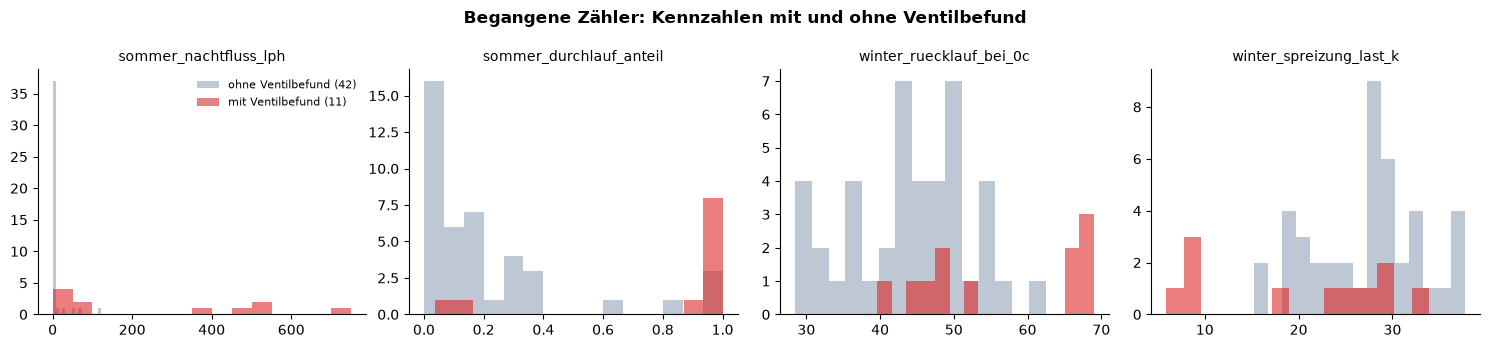

In [18]:
vergleich = kz.join(labels[["ventil", "daemmung"]], how="inner")
zeige = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "winter_spreizung_last_k"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, spalte in zip(axes, zeige):
    for wert, farbe, name in ((False, "#94A3B8", "ohne Ventilbefund"), (True, "#DC2626", "mit Ventilbefund")):
        werte = vergleich.loc[vergleich["ventil"] == wert, spalte].dropna()
        ax.hist(werte, bins=15, alpha=0.6, color=farbe, label=f"{name} ({len(werte)})")
    ax.set_title(spalte, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Begangene Zähler: Kennzahlen mit und ohne Ventilbefund", fontweight="bold")
fig.tight_layout()
plt.show()

- Erster Blick, ob die Kennzahlen die Befunde trennen: je Kennzahl ein Histogramm für begangene Zähler mit und ohne Ventilbefund.

- Der Sommer-Durchlaufanteil trennt das Ventil fast allein: 9 der 11 Zähler mit Ventilbefund hatten im Sommer 2024 in mindestens 90 % der Nachtstunden Durchfluss, ohne Befund nur 3 von 42. Im Median liefen bei den Ventilfällen nachts 67 l/h durch, bei den anderen 0 l/h.
- Auch im Winter gibt es Unterschiede: Rücklauf bei 0 °C im Median 53 °C statt 45 °C, Spreizung unter Last kleiner (24,6 statt 28,2 K). Das passt zur Physik: Läuft Wasser ungenutzt durch, kommt es heiß zurück. Die Verteilungen überlappen aber stark.
- Ausgangslage für die Modelle: Mit dem Sommer ist das Ventil leicht zu finden. Offen ist, ob ein Modell es schon im Winter sieht und ob es für die anderen Fehlerarten überhaupt ein Signal gibt.

## 8 Ergebnis speichern

- Schreibt die drei Dateien für die Notebooks 26 bis 29.

In [19]:
stunden[["zaehler", "timestamp", *KANAELE]].to_parquet(PROCESSED / "modell_stunden.parquet", index=False)
kz.to_csv(PROCESSED / "modell_kennzahlen.csv")
labels.to_csv(PROCESSED / "modell_labels.csv")
for name in ("modell_stunden.parquet", "modell_kennzahlen.csv", "modell_labels.csv"):
    print(f"{name:26s} {(PROCESSED / name).stat().st_size / 1e6:6.1f} MB")

modell_stunden.parquet       18.7 MB
modell_kennzahlen.csv         0.0 MB
modell_labels.csv             0.0 MB


- Alle drei Dateien liegen in `data/processed/` und damit nicht im Repo.
- `modell_labels.csv` enthält keine Adressen, nur Zählernummer, Datum, Labels und die Straßennummer.

## Zusammenfassung & Bewertung

**Ergebnis**
- `modell_stunden.parquet`: 2,1 Mio. Stundenzeilen von 93 Zählern, mit Außentemperatur. Gebraucht in Notebook 27 und 28.
- `modell_kennzahlen.csv`: 14 Kennzahlen je Zähler (91 Zähler), nur aus Daten vor der Begehung. Gebraucht in Notebook 26, 27 und 29.
- `modell_labels.csv`: 6 Labels je begangenem Zähler (56), Datum, Straßennummer. Gebraucht in Notebook 26 bis 29.

**Belastbar**
- Dieselbe Datenbasis wie in Notebook 00: dieselben 93 bereinigten Zählerreihen, nichts neu gefiltert.
- Saubere zeitliche Trennung: Keine Kennzahl enthält Messungen nach der ersten Begehung eines Zählers.
- Das Ventil hat ein klares Signal: 9 von 11 Fällen laufen im Sommer nachts durch, gegen 3 von 42 ohne Befund.

**Schwach**
- Wenige Fälle: 11 Ventilfälle und 9 verkleinerte Verträge. Jede Kennzahl, die später auf diesen Labels gemessen wird, braucht ein Unsicherheitsintervall.
- Die Gegenbeispiele sind meist leere Kästchen. Bei Filter, Durchfluss und Dämmung steht nur 4- bis 8-mal ein ausdrückliches „nein“. „Leer ist nein“ kann die Labels verwässern.
- Temperatur ist bei zwei Dritteln gesetzt. Das zeigt eher, dass der Monteur fast überall den Sollwert gesenkt hat, als einen Fehler der Station.
- Der Anschlusswert in `Nodes_Edges.ods` ist teilweise schon der Stand nach der Begehung. Für die Überdimensionierung taugt er nicht als Bezug; dafür gibt es `auslastung_vertrag`.

**Offen**
- 37 der 93 Zähler haben keine Begehung und damit kein Label. Sie können nicht zum Prüfen dienen; die Modelle schätzen sie in Notebook 29 trotzdem ein.
- Zwei Winter lassen sich nur mit 41 Zählern vergleichen, weil die übrigen erst 2023 dazukamen.